# Advertising Spend and Sales Volume

**Question.** How closely does a simple linear regression fit the relationship between advertising budget and sales volume?

The example comes from a coursework assignment with ten monthly observations. Budget is in thousands of dollars and sales are in thousands of units.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
data = pd.DataFrame({
    "Month": range(1, 11),
    "Advertising spend ($000)": [3, 5, 2, 7, 8, 1, 4, 6, 9, 10],
    "Unit sales (000)": [6, 9, 4, 10, 12, 3, 7, 8, 13, 15],
})
display(data)

,Month,Advertising spend ($000),Unit sales (000)
0,1,3,6
1,2,5,9
2,3,2,4
3,4,7,10
4,5,8,12
5,6,1,3
6,7,4,7
7,8,6,8
8,9,9,13
9,10,10,15


## Fit and evaluate

Fit ordinary least squares with an intercept. Compare in-sample R² with leave-one-out mean absolute error (MAE), where each prediction comes from a fit that excludes that observation.

In [2]:
spend = data["Advertising spend ($000)"].to_numpy()
sales = data["Unit sales (000)"].to_numpy()
design = np.column_stack([np.ones(len(spend)), spend])
intercept, slope = np.linalg.lstsq(design, sales, rcond=None)[0]
fitted = design @ [intercept, slope]
residuals = sales - fitted
r_squared = 1 - np.sum(residuals ** 2) / np.sum((sales - sales.mean()) ** 2)

held_out = np.empty(len(sales))
for i in range(len(sales)):
    training = np.arange(len(sales)) != i
    coefficients = np.linalg.lstsq(design[training], sales[training], rcond=None)[0]
    held_out[i] = design[i] @ coefficients
mae = np.mean(np.abs(sales - held_out))

assert np.isclose(r_squared, 0.9725691893)
print(f"Fitted sales (000) = {intercept:.2f} + {slope:.2f} × spend ($000)")
print(f"In-sample R²: {r_squared:.3f}")
print(f"Leave-one-out MAE: {mae * 1_000:,.0f} units")
print(f"Within this sample, ${1_000:,} more spend is associated with {slope * 1_000:,.0f} more units sold.")

Fitted sales (000) = 1.73 + 1.27 × spend ($000)
In-sample R²: 0.973
Leave-one-out MAE: 562 units
Within this sample, $1,000 more spend is associated with 1,267 more units sold.


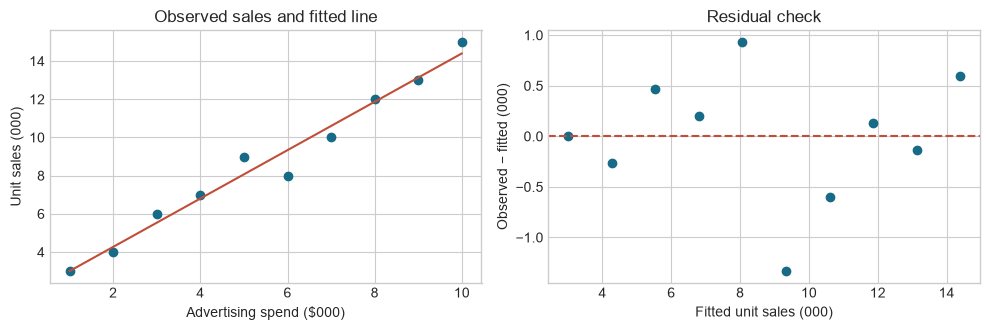

In [3]:
order = np.argsort(spend)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].scatter(spend, sales, color="#176B87")
axes[0].plot(spend[order], fitted[order], color="#C04E39")
axes[0].set(title="Observed sales and fitted line", xlabel="Advertising spend ($000)", ylabel="Unit sales (000)")
axes[1].scatter(fitted, residuals, color="#176B87")
axes[1].axhline(0, color="#C04E39", linestyle="--")
axes[1].set(title="Residual check", xlabel="Fitted unit sales (000)", ylabel="Observed − fitted (000)")
fig.tight_layout()
plt.show()

**Interpretation.** The line fits these ten observations closely. The sample is too small to establish a reliable production forecast. The association may reflect other factors and does not establish that additional spend caused higher sales. Validate on later periods, and stay within the observed budget range when interpreting the fit.